# Wine Quality Data Analysis

## 1. Introduction

### 1.1 Project Overview

This project focuses on Exploratory Data Analysis (EDA) and data preprocessing using the Wine Quality dataset.

The dataset contains physicochemical properties of wine samples and their corresponding quality ratings. The analysis aims to investigate the characteristics of the dataset, identify data quality issues, examine relationships between variables, and prepare the data for potential machine learning applications.

The project is conducted using Python in Jupyter Notebook as part of the **Big Data and Energy Data Analysis** course.

### 1.2 Project Objectives

The main objectives of this analysis are to:

1. Load and examine the Wine Quality dataset.
2. Identify and handle missing values.
3. Explore descriptive statistics to understand the dataset.
4. Detect and investigate outliers using boxplots and the Interquartile Range (IQR) method.
5. Visualize the distribution of wine quality ratings.
6. Examine correlations between physicochemical properties and wine quality.
7. Investigate relationships between variables using a scatter plot matrix.

### 1.3 Tools and Libraries

The analysis uses the following Python libraries:

- **Pandas:** Data loading, manipulation, and preprocessing.
- **NumPy:** Numerical operations.
- **Matplotlib:** Statistical visualizations.
- **Seaborn:** Advanced statistical visualizations.

### 1.4 Analysis Workflow

The analysis follows five main stages:

1. Data loading and initial examination.
2. Data preprocessing and missing-value treatment.
3. Descriptive statistics and outlier analysis.
4. Exploratory data visualization.
5. Interpretation of findings and conclusions.

## 2. Dataset Loading and Initial Examination

### 2.1 Dataset Description

The Wine Quality dataset contains physicochemical measurements of wine samples and their associated quality ratings.

The dataset consists of **1,599 observations and 12 columns**, including 11 input features and one target variable (`quality`).

The physicochemical features include:

- Fixed acidity
- Volatile acidity
- Citric acid
- Residual sugar
- Chlorides
- Free sulfur dioxide
- Total sulfur dioxide
- Density
- pH
- Sulphates
- Alcohol

The `quality` variable represents the quality rating assigned to each wine sample.

### 2.2 Loading the Dataset

**Objective:** Load the dataset into a Pandas DataFrame and examine its initial structure.

**Methodology:** The `pd.read_csv()` function is used to import the CSV file, while the `head()` method displays the first five observations.

This initial examination helps verify that the dataset has been loaded correctly and provides an overview of the variables available for analysis.

In [1]:
import pandas as pd
# Load the data
df = pd.read_csv("../data/winequality.csv", sep=",")
# Examine the data
display(df.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5.0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5.0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5.0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6.0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5.0


### 2.3 Initial Data Examination — Interpretation

The initial examination confirms that the dataset contains 1,599 wine samples and 12 variables.

The first five observations provide an overview of the physicochemical measurements and their corresponding wine quality ratings.

The dataset includes 11 numerical input features representing different chemical properties of wine, while `quality` serves as the target variable.

These features provide the foundation for investigating relationships between wine characteristics and quality ratings.

**Key Observation:** The dataset has been successfully loaded, and the variables are available for further exploratory analysis and preprocessing.

## 3. Data Preprocessing

### 3.1 Missing Value Analysis and Treatment

**Objective:** Identify and handle missing values to improve data completeness and prepare the dataset for further analysis.

**Methodology:**

Missing values are identified using the `isnull().sum()` function, which calculates the number of missing observations in each column.

Mean imputation is then applied using `fillna(df.mean())`, replacing missing numerical values with their corresponding column averages.

Finally, the dataset is checked again to verify that the missing values have been handled.

Mean imputation is a simple preprocessing technique that preserves the number of observations. However, it may influence the distribution and variability of the data.

In [2]:
# Check for missing values
display(df.isnull().sum())
# Impute missing values with the mean
df.fillna(df.mean(), inplace=True)
# Verify that there are no more missing values
display(df.isnull().sum())

fixed acidity           73
volatile acidity        94
citric acid             79
residual sugar          79
chlorides               62
free sulfur dioxide     69
total sulfur dioxide    76
density                 84
pH                      94
sulphates               97
alcohol                 64
quality                 83
dtype: int64

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

### 3.2 Results and Interpretation

The missing-value analysis is used to evaluate the completeness of the Wine Quality dataset before preprocessing.

Missing observations are addressed using mean imputation, which replaces missing numerical entries with their respective column averages.

The dataset is subsequently examined to verify whether the missing values have been successfully handled.

**Key Finding:** Mean imputation provides a straightforward approach to handling incomplete numerical data while preserving the dataset's original number of observations.

**Limitation:** Mean imputation can reduce variability and influence statistical relationships. Furthermore, because `quality` represents discrete target ratings, imputing missing quality values with the mean may introduce unrealistic ratings. Missing target values should be treated separately when developing predictive models.

## 4. Descriptive Statistical Analysis

### 4.1 Statistical Summary of the Dataset

**Objective:** Examine the statistical characteristics of the Wine Quality dataset to understand the distribution, central tendency, and variability of its numerical features.

**Methodology:**

Descriptive statistical analysis is performed using the Pandas `describe()` function, which generates a summary of the numerical variables.

The summary includes:

- **Count:** Number of non-missing observations.
- **Mean:** Average value of each variable.
- **Standard Deviation:** Measure of variability around the mean.
- **Minimum (min):** Smallest observed value.
- **25th Percentile (Q1):** Value below which 25% of observations fall.
- **50th Percentile (Median):** Middle value of the distribution.
- **75th Percentile (Q3):** Value below which 75% of observations fall.
- **Maximum (max):** Largest observed value.

These statistics help identify potential irregularities, variations in feature distributions, and unusually high or low observations that may require further investigation.

In [3]:
# Examine the sta tistical summary of the features
display(df.describe())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.320183,0.526648,0.271336,2.542105,0.087310,15.884967,46.896257,0.996745,3.312219,0.657144,10.417101,5.636544
std,1.691527,0.172716,0.189322,1.391232,0.046136,10.287779,32.145059,0.001857,0.148811,0.165407,1.035983,0.789772
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.200000,0.400000,0.100000,1.900000,0.070500,8.000000,23.000000,0.995655,3.220000,0.550000,9.500000,5.000000
50%,8.000000,0.526648,0.270000,2.200000,0.080000,14.000000,40.000000,0.996745,3.312219,0.630000,10.200000,6.000000
75%,9.100000,0.630000,0.420000,2.600000,0.089000,21.000000,61.000000,0.997800,3.400000,0.720000,11.000000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.000000,8.000000


### 4.2 Results and Interpretation

The descriptive statistical summary provides insights into the distribution and variability of the physicochemical properties of the wine samples.

The mean and median values help assess the central tendency of each feature. Differences between these values may indicate skewed distributions.

The standard deviation provides information about the variability of observations, while the minimum, maximum, and quartile values help identify the spread of the data.

In particular, the `total sulfur dioxide` variable warrants further investigation because unusually high observations may indicate potential outliers.

Large differences between the maximum value and the 75th percentile can suggest the presence of extreme observations.

**Key Finding:** Descriptive statistics provide a foundation for identifying potentially unusual observations and determining which variables require further investigation.

However, extreme observations are not necessarily erroneous. Additional analysis using boxplots and the Interquartile Range (IQR) method is required to investigate potential outliers.

## 5. Outlier Detection and Treatment

### 5.1 Outlier Detection Using Boxplots

**Objective:** Identify potential outliers in the `total sulfur dioxide` variable and examine the distribution of its observations.

**Methodology:**

Outliers are observations that differ substantially from the majority of values in a dataset. They may arise from natural variability, measurement errors, or unusual conditions.

A boxplot is used to visualize the distribution of `total sulfur dioxide` and identify potentially extreme observations.

The boxplot displays:

- **Median:** The central value of the distribution.
- **First Quartile (Q1):** The 25th percentile.
- **Third Quartile (Q3):** The 75th percentile.
- **Interquartile Range (IQR):** The difference between Q3 and Q1.
- **Whiskers:** The range of observations within the boxplot's outlier thresholds.
- **Outliers:** Observations outside the whiskers.

This visualization helps determine whether further outlier treatment is necessary.

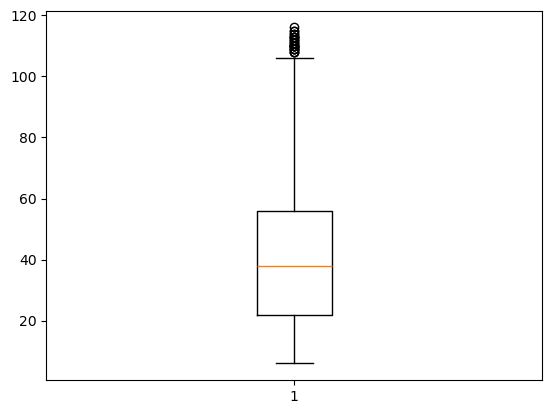

In [12]:
import numpy as np
import matplotlib.pyplot as plt
# Create a box plot of the "total sulfur dioxide" feature

plt.boxplot(x=df["total sulfur dioxide"])

# Save the outlier detection boxplot as a high-resolution image
plt.savefig("../figure/total_sulfur_dioxide_boxplot.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

### 5.2 Boxplot Interpretation

The boxplot provides a visual representation of the distribution of `total sulfur dioxide` values.

Observations extending beyond the whiskers are identified as potential outliers based on the boxplot's statistical thresholds.

These observations may indicate unusually high sulfur dioxide concentrations compared with the majority of wine samples.

**Key Observation:** The boxplot helps identify observations that require further investigation. However, values classified as statistical outliers are not necessarily measurement errors.

The Interquartile Range (IQR) method is subsequently applied to identify and remove observations outside the defined thresholds, following the lab instructions.

### 5.3 Outlier Treatment Using the Interquartile Range (IQR) Method

**Objective:** Identify and remove extreme observations in the `total sulfur dioxide` feature using a statistical threshold.

**Methodology:**

The Interquartile Range (IQR) method identifies potential outliers based on the spread of the middle 50% of observations.

The IQR is calculated as:

\[
IQR = Q3 - Q1
\]

The lower and upper thresholds are defined as:

\[
\text{Lower Bound} = Q1 - 1.5 \times IQR
\]

\[
\text{Upper Bound} = Q3 + 1.5 \times IQR
\]

Observations falling below the lower bound or above the upper bound are classified as potential outliers.

Following the lab instructions, observations outside these thresholds are removed from the dataset.

This approach reduces the influence of extreme values on subsequent exploratory analysis. However, removing outliers may also eliminate valid observations, so the method should be applied with caution.

In [5]:
# Calculate the IQR for the "total sulfur dioxide" feature
Q1 = df["total sulfur dioxide"].quantile(0.25)
Q3 = df["total sulfur dioxide"].quantile(0.75)
IQR = Q3 - Q1
# Remove aberrant data points
df = df[~((df["total sulfur dioxide"] < (Q1 - 1.5 * IQR)) | (df["total sulfur dioxide"] > (Q3 + 1.5 * IQR)))]

### 5.4 Results and Interpretation of Outlier Treatment

The IQR method is applied to the `total sulfur dioxide` variable to identify observations outside the calculated lower and upper thresholds.

The dataset is filtered to retain observations that fall within the acceptable IQR-based range.

**Interpretation:**

This procedure reduces the influence of extreme `total sulfur dioxide` observations on subsequent statistical analysis and visualizations.

However, the removal of outliers also reduces the number of observations available for analysis and may affect the distribution of the dataset.

**Key Finding:** The IQR method provides a systematic approach for identifying and treating statistical outliers, although the removed observations are not necessarily erroneous.

The resulting dataset is used for the subsequent exploratory visualizations.

## 6. Wine Quality Distribution Analysis

### 6.1 Distribution of Wine Quality Ratings

**Objective:** Examine the frequency distribution of wine quality ratings to understand how the samples are distributed across different quality levels.

**Methodology:**

A histogram is generated using Matplotlib to visualize the distribution of the `quality` variable.

The histogram displays:

- **X-axis:** Wine quality ratings.
- **Y-axis:** Frequency of observations within each histogram bin.

This visualization helps identify frequently occurring quality ratings, less common ratings, and potential imbalances in the target variable.

Understanding the distribution of wine quality is important for exploratory analysis and can provide useful insights for future predictive modeling.

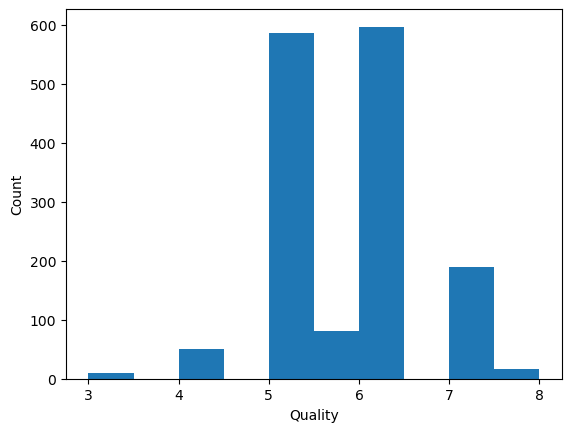

In [9]:
# Create a histogram of the target variable
import matplotlib.pyplot as plt

plt.hist(df["quality"])
plt.xlabel("Quality")
plt.ylabel("Count")

# Save the histogram as a high-resolution PNG image
plt.savefig("../figure/wine_quality_distribution.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

### 6.2 Results and Interpretation

The histogram illustrates the frequency distribution of wine quality ratings across the dataset.

The visualization helps identify which quality ratings occur most frequently and whether observations are concentrated within a particular range.

The relative heights of the histogram bars indicate differences in the number of observations across quality intervals.

**Key Observation:** Examining the distribution of the target variable helps identify potential class imbalance, which may influence the performance and evaluation of future machine learning models.

**Limitation:** Because missing values were treated using mean imputation, the distribution may include imputed quality values that do not correspond to genuine discrete ratings. This should be considered when interpreting the histogram.

## 7. Correlation Analysis

### 7.1 Correlation Matrix and Heatmap

**Objective:** Investigate the strength and direction of linear relationships between the physicochemical properties of wine and the quality ratings.

**Methodology:**

A correlation matrix is calculated using the Pandas `corr()` function, which computes Pearson correlation coefficients by default.

The correlation coefficients range from -1 to +1:

- **+1:** Perfect positive linear correlation.
- **0:** No linear correlation.
- **-1:** Perfect negative linear correlation.

A heatmap is generated using Seaborn to visualize the correlation matrix.

The heatmap uses color intensity to represent the strength and direction of relationships, while numerical annotations display the correlation coefficients.

This analysis helps identify features associated with wine quality and detect potential multicollinearity among predictor variables.

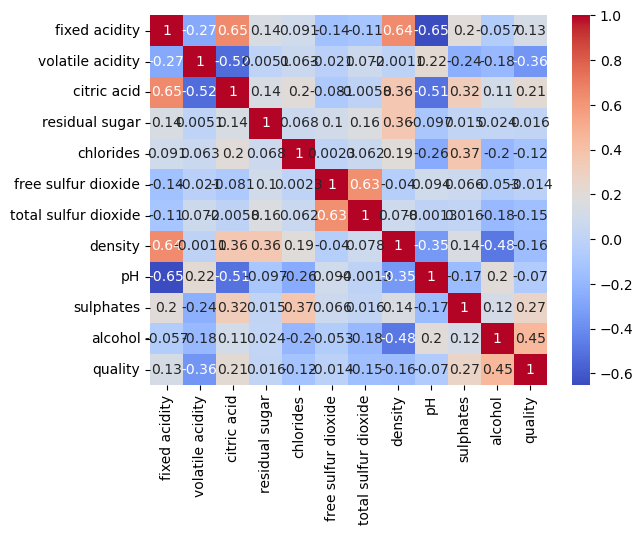

In [10]:
# Create a heatmap of the correlation between the features
import seaborn as sns

corr = df.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")

# Save the correlation heatmap as a high-resolution PNG
plt.savefig("../figure/correlation_heatmap.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

### 7.2 Results and Interpretation

The correlation heatmap illustrates the strength and direction of linear relationships among the physicochemical properties of wine and their quality ratings.

Positive correlation coefficients indicate that two variables tend to increase together, while negative coefficients indicate that one variable tends to decrease as the other increases.

Correlation coefficients closer to zero suggest weaker linear relationships.

The heatmap allows the identification of variables that may be associated with wine quality and highlights relationships between predictor variables that could indicate multicollinearity.

**Key Observations:**

- Relationships between physicochemical features and wine quality can help identify potentially informative variables for further analysis.
- Strong correlations among predictor variables may indicate redundant information.
- Correlation does not establish causation; therefore, observed relationships should not be interpreted as direct cause-and-effect relationships.

**Limitation:** Missing-value imputation and outlier removal may influence the calculated correlation coefficients. Additionally, Pearson correlation measures linear relationships and may not capture nonlinear associations.

**Key Finding:** The correlation matrix provides an overview of feature relationships and supports further investigation of variables potentially associated with wine quality.

## 8. Scatter Plot Matrix Analysis

### 8.1 Exploring Relationships Between Wine Characteristics

**Objective:** Examine the distributions and pairwise relationships among the physicochemical properties of wine and investigate how these relationships vary across quality ratings.

**Methodology:**

A scatter plot matrix is generated using Seaborn's `pairplot()` function.

The visualization displays pairwise relationships between numerical features, with observations differentiated according to the `quality` variable.

The scatter plot matrix includes:

- **Diagonal plots:** Show the distribution of individual physicochemical features.
- **Off-diagonal scatter plots:** Illustrate relationships between pairs of numerical variables.
- **Color grouping (`hue="quality"`):** Distinguishes observations according to their wine quality ratings.

This visualization helps identify potential correlations, clusters, nonlinear relationships, and unusual observations.

It also provides an opportunity to examine whether wines with different quality ratings exhibit distinguishable physicochemical characteristics.

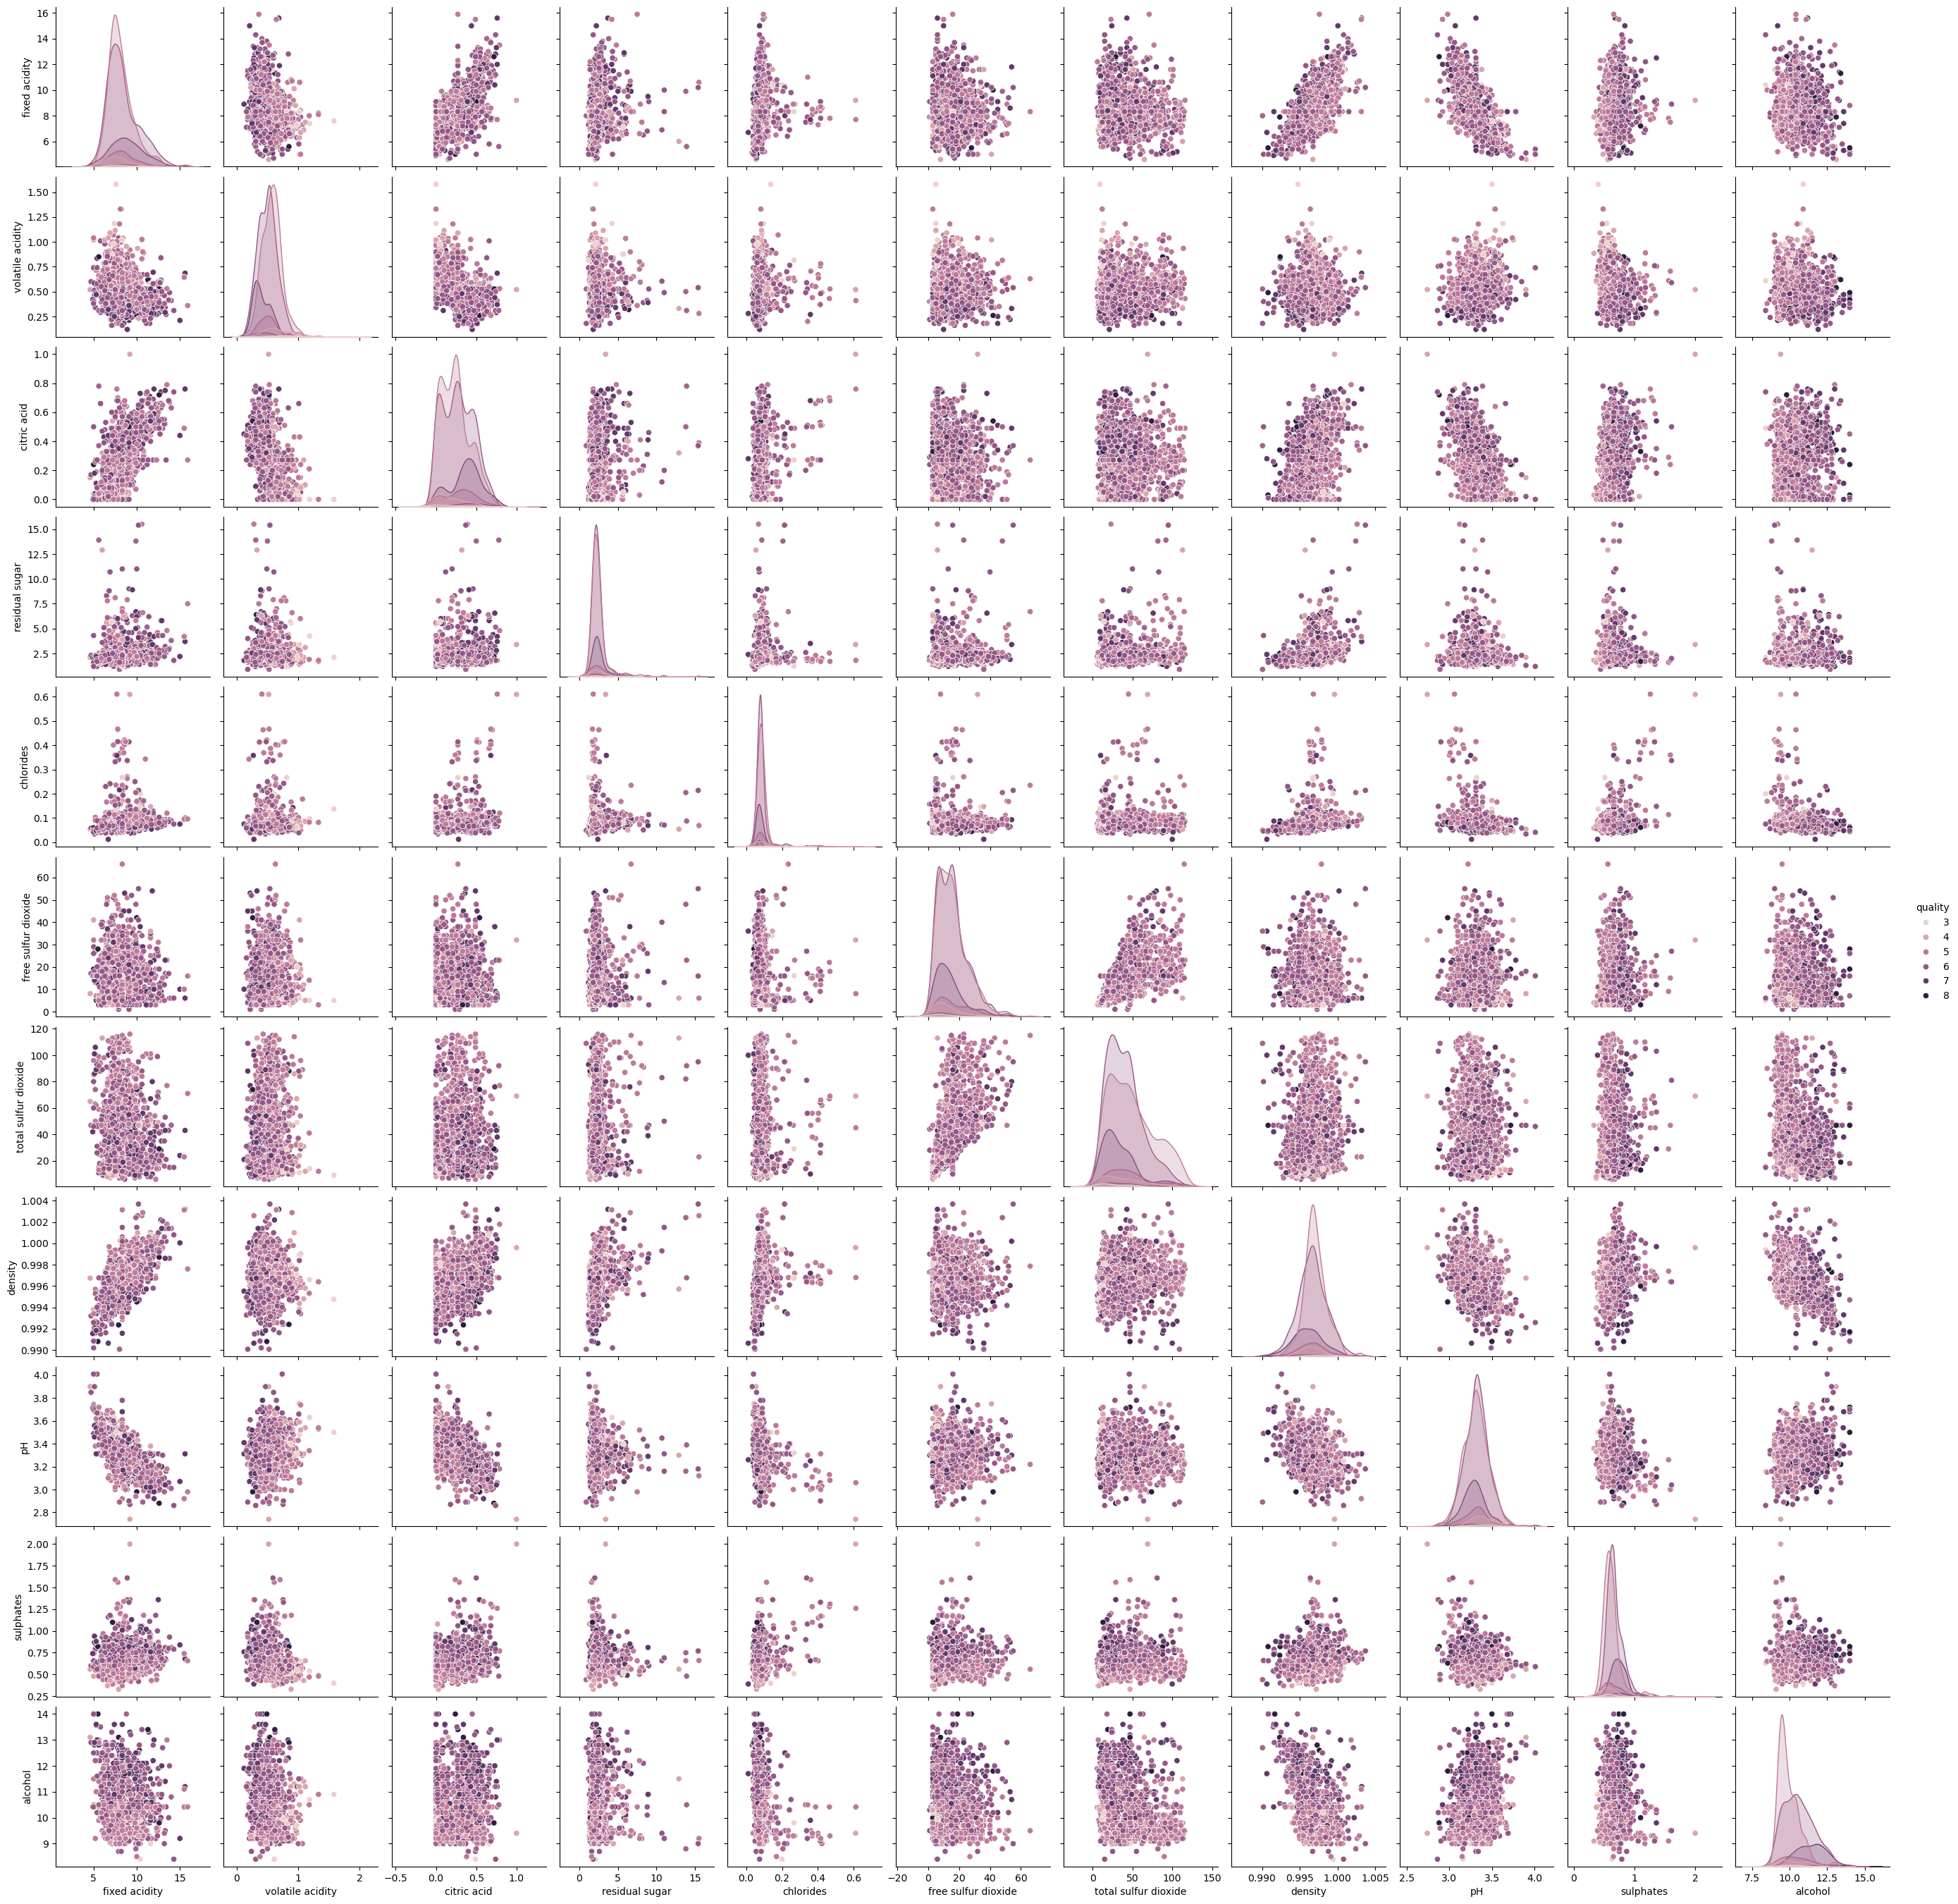

In [11]:
# Create a scatter plot matrix
# sns.pairplot(data=df, vars=["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol"], hue="quality")

# Generate the scatter plot matrix
g = sns.pairplot(
    data=df,
    vars=[
        "fixed acidity", "volatile acidity", "citric acid",
        "residual sugar", "chlorides", "free sulfur dioxide",
        "total sulfur dioxide", "density", "pH",
        "sulphates", "alcohol"
    ],
    hue="quality"
)

# Save the complete scatter plot matrix
g.savefig("../figure/scatter_plot_matrix.png",
          dpi=300,
          bbox_inches="tight")

plt.show()

### 8.2 Results and Interpretation

The scatter plot matrix provides a comprehensive visualization of the relationships among the physicochemical properties of wine.

The diagonal plots illustrate the distributions of individual features, while the off-diagonal plots reveal how pairs of variables vary together.

The color grouping based on wine quality ratings allows comparisons between observations belonging to different quality categories.

**Key Observations:**

- The scatter plots help identify potential positive and negative relationships between physicochemical features.
- Differences in the distributions of observations may indicate that certain features are more informative for distinguishing wine quality ratings.
- Overlapping observations across quality categories may suggest that individual physicochemical properties are insufficient to clearly separate wine quality levels.
- Unusual observations or nonlinear patterns may warrant further investigation.

**Limitations:**

The scatter plot matrix provides visual evidence of relationships but does not establish statistical significance or causation.

Additionally, the large number of features may make some relationships difficult to interpret because of overlapping observations.

**Key Finding:** The scatter plot matrix complements the correlation heatmap by providing a visual examination of feature relationships and potential differences across wine quality ratings.

## 9. Conclusion and Key Findings

### 9.1 Project Summary

This project explored the Wine Quality dataset through Exploratory Data Analysis (EDA) and data preprocessing techniques using Python.

The analysis involved examining the dataset, identifying and handling missing values, investigating descriptive statistics, detecting and treating potential outliers, and visualizing relationships between physicochemical properties and wine quality ratings.

### 9.2 Key Findings

**1. Dataset Structure**

The dataset contains 1,599 wine samples and 12 variables, consisting of 11 physicochemical features and one target variable (`quality`).

**2. Missing Value Treatment**

Missing values were investigated using Pandas and treated using mean imputation, following the guided lab methodology.

This approach preserves the number of observations during imputation but may influence the statistical distribution of the variables.

**3. Descriptive Statistical Analysis**

Descriptive statistics provided information about the central tendency, variability, and range of the physicochemical features.

The statistical summary helped identify variables requiring further investigation for potential extreme observations.

**4. Outlier Detection and Treatment**

A boxplot and the Interquartile Range (IQR) method were used to investigate potential outliers in the `total sulfur dioxide` variable.

Observations outside the calculated IQR thresholds were excluded from the subsequent analysis.

**5. Wine Quality Distribution**

A histogram was used to examine the frequency distribution of wine quality ratings.

This visualization provides an overview of the target variable and supports the identification of potential imbalances between quality levels.

**6. Correlation Analysis**

A correlation heatmap was generated to investigate linear relationships among the physicochemical features and wine quality ratings.

The analysis provides a foundation for identifying potentially informative features and examining relationships among predictor variables.

**7. Scatter Plot Matrix**

A scatter plot matrix was used to visualize pairwise relationships among physicochemical features, with observations differentiated by wine quality ratings.

This visualization complements the correlation heatmap by allowing a more detailed examination of feature distributions and relationships.

### 9.3 Limitations

Several limitations should be considered when interpreting the results:

- Mean imputation may reduce variability and influence correlations between variables.
- Imputing the `quality` target variable may introduce values that do not correspond to genuine discrete ratings.
- Removing statistical outliers may exclude valid observations and alter the dataset distribution.
- Correlation analysis identifies linear associations but does not establish causation.
- The exploratory analysis does not evaluate the predictive performance of a machine learning model.

### 9.4 Recommendations for Future Work

Future analysis could include:

1. Comparing mean imputation with alternative missing-value treatment methods.
2. Investigating outliers across additional physicochemical features.
3. Examining which features have the strongest associations with wine quality.
4. Applying feature scaling and selection techniques where appropriate.
5. Developing and evaluating machine learning models to predict wine quality ratings.

### 9.5 Final Remarks

This project demonstrates the importance of exploratory data analysis and data preprocessing in understanding dataset characteristics and preparing data for further analysis.

The techniques applied provide a structured foundation for investigating wine quality and support future machine learning applications.